# Lab 7A: Optical Satellite Imagery — Spectral Bands & False Colour

> **Colab note:** This notebook is designed to run on **Google Colab**. [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amtseismo/EPS166/blob/main/notebooks/07a_optical_false_color.ipynb)

## Introduction

Optical satellites record reflected sunlight across multiple wavelength bands simultaneously. By choosing which bands to assign to the red, green, and blue display channels, we can reveal surface properties — vegetation, mineralogy, moisture — that are invisible to the human eye.

In this lab you will:
1. Explore multispectral Sentinel-2 imagery over Crater Lake, Oregon
2. Download and interpret a Sentinel-2 scene of your own choosing

## Learning objectives

By the end of this lab you will be able to:

- Load and display individual spectral bands from a multispectral satellite image
- Construct true-colour, colour-infrared (CIR), and geology composites
- Calculate and interpret NDVI
- Query and download Sentinel-2 scenes from the Copernicus Data Space API

## Notebook outline

1. [Setup](#setup)
2. [Part I: Crater Lake — spectral exploration](#part-i-crater-lake--spectral-exploration)
3. [Part II: Your own scene](#part-ii-your-own-scene)


## Setup

Install and import required packages.


In [ ]:
%pip install -q rasterio pystac-client planetary-computer

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
from rasterio.enums import Resampling
from skimage.registration import phase_cross_correlation
from scipy.ndimage import uniform_filter
import urllib.request, os, warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.dpi": 130, "axes.grid": False})
print("Setup complete.")


Note: you may need to restart the kernel to use updated packages.
Setup complete.


---

## Part I: Crater Lake — spectral band exploration

Crater Lake, Oregon occupies the caldera of Mount Mazama, a volcano that collapsed ~7,700 years ago. It is one of the deepest lakes in the world (~590 m) and is surrounded by dense old-growth conifer forest. The scene contains four spectrally distinct surface types:

| Surface | Spectral character |
|---|---|
| **Deep lake water** | Some penetration in blue; absorbs strongly in green, NIR, and SWIR |
| **Dense conifer forest** | Absorbs red (chlorophyll); reflects strongly in NIR (leaf cell structure) |
| **Bare volcanic rock** | Intermediate reflectance; SWIR reveals mineralogy and alteration |
| **Snow / ice** | Bright in all visible bands; dark in SWIR (water in ice absorbs it) |

We begin with a true-colour reference image so you can orient yourself in the scene, then examine individual spectral bands, and finally build false-colour composites that reveal features the eye cannot see.

### Download the Crater Lake scene

In [3]:
# Pre-clipped Sentinel-2 L2A bands over Crater Lake (10 m resolution)
# Bands: B02 (Blue), B03 (Green), B04 (Red), B08 (NIR), B11 (SWIR-1), B12 (SWIR-2)
CRATER_BASE = (
    "https://raw.githubusercontent.com/amtseismo/EPS166/"
    "main/datasets/CraterLake/"
)
CRATER_BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]

for band in CRATER_BANDS:
    fname = f"CraterLake_{band}.tif"
    if not os.path.exists(fname):
        print(f"Downloading {fname}...")
        urllib.request.urlretrieve(CRATER_BASE + fname, fname)
print("All Crater Lake bands downloaded.")


All Crater Lake bands downloaded.


### Load the bands

In [4]:
def load_band(path, upsample_shape=None):
    """Load a single-band GeoTIFF. Optionally resample to upsample_shape (rows, cols)."""
    with rasterio.open(path) as src:
        if upsample_shape:
            arr = src.read(1, out_shape=upsample_shape,
                           resampling=Resampling.bilinear).astype(np.float32)
        else:
            arr = src.read(1).astype(np.float32)
        transform = src.transform
        nodata = src.nodata
    if nodata is not None:
        arr[arr == nodata] = np.nan
    return arr, transform

def pct(arr, lo=2, hi=98):
    """Percentile stretch to [0,1] for display."""
    vmin, vmax = np.nanpercentile(arr, [lo, hi])
    return np.clip((arr - vmin) / (vmax - vmin), 0, 1)

# Load 10 m bands
b02, tf = load_band("CraterLake_B02.tif")   # Blue
b03, _  = load_band("CraterLake_B03.tif")   # Green
b04, _  = load_band("CraterLake_B04.tif")   # Red
b08, _  = load_band("CraterLake_B08.tif")   # NIR

# SWIR bands are 20 m — resample to match 10 m grid
shape10 = b04.shape
b11, _  = load_band("CraterLake_B11.tif", upsample_shape=shape10)  # SWIR-1
b12, _  = load_band("CraterLake_B12.tif", upsample_shape=shape10)  # SWIR-2

print(f"Image size: {b04.shape[0]} x {b04.shape[1]} pixels  ({b04.shape[0]*10/1000:.1f} x {b04.shape[1]*10/1000:.1f} km)")

# Store scene CRS and transform for use in the crop cell below
with rasterio.open("CraterLake_B04.tif") as _src:
    scene_crs = _src.crs
    scene_transform = _src.transform

Image size: 1800 x 2222 pixels  (18.0 x 22.2 km)


In [5]:
def make_composite(r, g, b, lo=2, hi=98):
    """Stack three bands into an RGB display array."""
    return np.dstack([pct(r, lo, hi), pct(g, lo, hi), pct(b, lo, hi)])

### True color — scene orientation

Before exploring individual bands, establish a reference. The true-color composite assigns the visible bands (Red→R, Green→G, Blue→B) to produce an image close to what your eye would see from space.

As you look at the image, locate the following features — you will return to them repeatedly in the sections below:

- **The lake** — the deep blue interior
- **Dense conifer forest** — dark green slopes surrounding the caldera
- **Bare volcanic rock** — the exposed caldera rim and walls
- **Wizard Island** — a small cinder cone in the western part of the lake, erupted *inside* the caldera after the collapse (~7,700 years ago and therefore younger than the caldera walls); look for a dark speck of rock surrounded by shallow water
- **Snow / ice patches** — bright white, typically on the upper rim


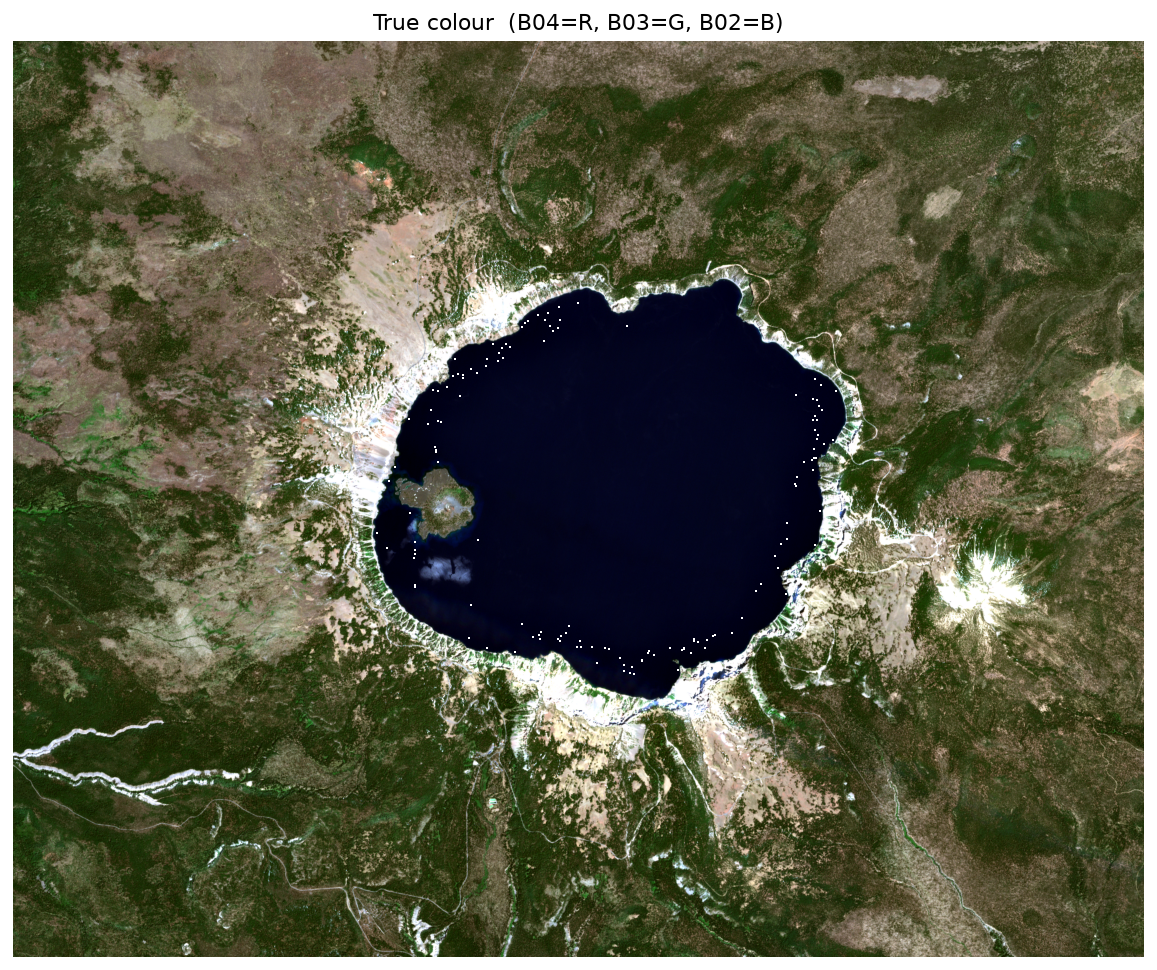

In [6]:
true_color = make_composite(b04, b03, b02)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(true_color)
ax.set_title("True colour  (B04=R, B03=G, B02=B)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()

> **Questions — true color:**
> 1. **Identify four surface types.** Find one clear example of each and describe its location (e.g. "northwest rim," "centre of the lake"). What visual clue — color, brightness, or texture — made you confident in each? *(You may notice small bright speckles over the dark lake water — these are likely sensor noise, which is most visible where the true signal is very low.)*
>    - Dense conifer forest
>    - Bare volcanic rock
>    - Deep lake water
>    - Snow or ice
> 2. **What makes this a "true color" image?** Which Sentinel-2 bands are assigned to the red, green, and blue display channels? Why does this combination produce an image that looks natural to the human eye when the satellite records many more wavelengths than just three?
> 3. **Limits of true color.** Look at the caldera rim. Can you distinguish different rock types or degrees of weathering, or does the bare rock appear fairly uniform? Keep this observation in mind when you reach the geology composite later in the lab.


### Visible bands — zoomed to Wizard Island

The deep open lake absorbs most incoming light uniformly across the visible spectrum, so a whole-scene view shows little difference between the Blue, Green, and Red bands. To see the spectral contrast that *does* exist in water, we zoom to the Wizard Island area, where shallow water near the shore, the bare volcanic rock of the island, and the deep surrounding lake are all present within a small area.

Each band is displayed in its own color map so the spectral identity of each panel is immediately visible. The color bar beneath each panel runs from **Absorbed** (little light returns to the sensor) to **Reflected** (a lot of light returns to the sensor):

- **Blue (B02):** Penetrates clear water more deeply than other visible wavelengths; also scattered by atmospheric particles and aerosols
- **Green (B03):** Captures peak vegetation reflectance in the visible — the reason leaves look green
- **Red (B04):** Absorbed by chlorophyll for photosynthesis; healthy vegetation appears dark here


In [7]:
import pyproj
from rasterio.transform import rowcol

# Wizard Island centre coordinate (WGS84)
WIZ_LAT, WIZ_LON = 42.939390, -122.148470

# scene_crs and scene_transform were captured in the load cell above
transformer = pyproj.Transformer.from_crs(
    "EPSG:4326", scene_crs, always_xy=True
)
wiz_x, wiz_y = transformer.transform(WIZ_LON, WIZ_LAT)
cy, cx = rowcol(scene_transform, wiz_x, wiz_y)
cy, cx = int(cy), int(cx)

pad = int(min(b04.shape) * 0.10)
rs = slice(max(0, cy - pad), cy + pad)
cs = slice(max(0, cx - pad), cx + pad)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
vis_bands = [
    (b02[rs, cs], "B02  Blue (0.49 µm)",  "Blues",  "Water penetration\natmospheric scattering"),
    (b03[rs, cs], "B03  Green (0.56 µm)", "Greens", "Peak vegetation reflectance\nin visible"),
    (b04[rs, cs], "B04  Red (0.66 µm)",   "Reds",   "Chlorophyll absorption\nfor photosynthesis"),
]
for ax, (band, title, cmap, subtitle) in zip(axes, vis_bands):
    im = ax.imshow(pct(band), cmap=cmap)
    ax.set_title(f"{title}\n{subtitle}", fontsize=10)
    ax.axis("off")
    cbar = plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.02, shrink=0.8)
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(["Absorbed", "Reflected"])

plt.suptitle("Visible bands — zoomed to Wizard Island (color maps match band color)", fontsize=12)
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'pyproj'

> **Questions — visible bands:**
> 1. Compare the three panels side by side, focusing on the area where Wizard Island meets the water. Which band looks noticeably different from the other two at the island's edge? Describe what you see.
> 2. Using the color bars as a guide — "Absorbed" means little light returns to the sensor, "Reflected" means a lot — look at the shallow water immediately around Wizard Island. Which band shows the highest reflectance there? Which shows the lowest?


In [ ]:
from scipy.ndimage import map_coordinates

# Eastward profile from Wizard Island rock into open water
profile_len = 200
start_r = pad
start_c = pad + int(pad * 0.15)     # slightly east of island centre, still on rock
end_r   = pad
end_c   = cs.stop - cs.start - 5    # eastern edge of the crop

rows_line = np.linspace(start_r, end_r, profile_len)
cols_line = np.linspace(start_c, end_c, profile_len)

b02_profile = map_coordinates(b02[rs, cs], [rows_line, cols_line], order=1)
b03_profile = map_coordinates(b03[rs, cs], [rows_line, cols_line], order=1)
b04_profile = map_coordinates(b04[rs, cs], [rows_line, cols_line], order=1)

distance_m = np.linspace(0, profile_len * 10, profile_len)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(distance_m, b02_profile, color="royalblue", label="B02  Blue (0.49 µm)")
ax.plot(distance_m, b03_profile, color="green",     label="B03  Green (0.56 µm)")
ax.plot(distance_m, b04_profile, color="firebrick", label="B04  Red (0.66 µm)")
ax.set_xlabel("Distance from island centre (m)")
ax.set_ylabel("Reflectance")
ax.set_title("Spectral profile: Wizard Island rock → open water (eastward transect)")
ax.legend()
plt.tight_layout()
plt.show()


> 3. Describe how the reflectance in each band changes as you move from the island rock into deeper water. Do all three bands behave the same way, or do they diverge?
> 4. The behaviour you see in the profile is driven by **absorption**. Water molecules vibrate naturally at frequencies that correspond to infrared wavelengths, but the overtones of those vibrations overlap with the red and green portions of the visible spectrum. Blue light is far enough from those resonance frequencies that it is absorbed much less readily.
>    - Which band on your profile penetrates deepest into the water column before its reflectance drops? Is this consistent with blue light being absorbed least?
>    - Which band drops off fastest from the shoreline? Is this consistent with red light being absorbed most strongly?
>    - If you were designing a sensor to estimate water depth in a clear lake, would you choose a wavelength close to or far from water's vibrational absorption bands? Why?
>    - All optical methods have a fundamental depth limit regardless of wavelength. What causes it?


### Near-Infrared: the vegetation band (B08, 0.84 µm)

The NIR band lies just beyond what the human eye can see, but it is one of the most information-rich bands in Earth observation. Two physical properties make it distinctive:

1. **Vegetation:** The internal cell structure of leaves — the spongy mesophyll layer — scatters NIR strongly upward. Healthy plants reflect ~40–50% of incident NIR, compared to ~5% of incident red.
2. **Water:** Liquid water absorbs NIR almost completely. The lake appears nearly black regardless of depth.

The dramatic contrast between these two responses is the physical basis for NDVI.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

for ax, band, title, subtitle in zip(
    axes,
    [b04, b08],
    ["B04  Red (0.66 µm)", "B08  NIR (0.84 µm)"],
    ["Chlorophyll absorbs here —\nvegetation appears dark",
     "Leaf cell structure reflects here —\nhealthy vegetation appears bright"],
):
    ax.imshow(pct(band), cmap="gray")
    ax.set_title(f"{title}\n{subtitle}", fontsize=10)
    ax.axis("off")

plt.suptitle("Red vs Near-Infrared: the contrast that underlies NDVI", fontsize=12)
plt.tight_layout()
plt.show()

> **Questions — NIR:**
> 1. How does the brightness of the forested slopes change between B04 and B08? What physical property of leaves explains this?
> 2. The lake is one of the clearest and deepest in the world. Does NIR penetrate it at all, or does it appear uniformly dark? What does this imply about using NIR for bathymetric mapping?
> 3. Examine the bare volcanic rock on the caldera rim. How much does its brightness change between B04 and B08 compared to the change in the forest? Why is the forest's response so much more dramatic?

### Shortwave-Infrared: mineralogy and moisture (B11, B12)

The SWIR bands (B11 at 1.61 µm and B12 at 2.19 µm) carry information invisible to the human eye but physically distinctive:

- **Ice and snow:** Water molecules in ice crystals absorb SWIR strongly. Snow that appears bright white in visible looks dark in SWIR — a key way to distinguish fresh snow from bright rock or sand.
- **Leaf water content:** Liquid water in plant leaves absorbs SWIR. Drier or stressed vegetation appears brighter in SWIR than well-watered vegetation.
- **Rock mineralogy:** Clay minerals and hydrothermal alteration products have diagnostic absorption features in the SWIR. The volcanic walls of the caldera may show subtle variation reflecting different rock types or weathering stages.

*Note: B11 and B12 are native 20 m resolution — resampled here to match the 10 m visible/NIR grid.*

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

swir_bands = [
    (b08, "B08  NIR (0.84 µm)", "(reference — vegetation bright,\nwater dark)"),
    (b11, "B11  SWIR-1 (1.61 µm)", "Leaf water content;\nsnow/ice appears dark"),
    (b12, "B12  SWIR-2 (2.19 µm)", "Clay minerals and hydrothermal\nalteration detectable"),
]
for ax, (band, title, subtitle) in zip(axes, swir_bands):
    ax.imshow(pct(band), cmap="gray")
    ax.set_title(f"{title}\n{subtitle}", fontsize=10)
    ax.axis("off")

plt.suptitle("NIR vs SWIR: moisture, ice, and mineralogy", fontsize=12)
plt.tight_layout()
plt.show()

> **Questions — SWIR:**
> 1. The most striking difference in B11 and B12 compared to NIR is how snow and ice appear. Describe what you observe and explain why ice absorbs SWIR so strongly.
> 2. Compare the forest brightness in B08 (NIR) vs B11 (SWIR-1). Does the forest appear brighter or darker in SWIR? What does this tell you about the water content of the trees?
> 3. Look carefully at the caldera walls in B12. Can you see colour or brightness variation that is not obvious in the visible bands? What geological process might produce that variation?

### False-colour composites

You have now seen how each wavelength region responds to the scene. We build two more composites that assign non-visible bands to display channels, revealing features that are invisible in the true-colour image you examined at the start.

| Composite | Band → Red | Band → Green | Band → Blue | Key use |
|---|---|---|---|---|
| **Colour Infrared (CIR)** | B08 NIR | B04 Red | B03 Green | Vegetation health, water depth |
| **Geology** | B12 SWIR-2 | B11 SWIR-1 | B04 Red | Mineralogy, discriminates snow from rock |

#### Colour Infrared / CIR (B08→R, B04→G, B03→B)

Replaces the blue display channel with red, green with red, and red with NIR. This "shifts" the display one channel toward longer wavelengths, making NIR information appear as red. Widely used in ecology and agriculture; originally designed to mimic wartime colour-infrared aerial film.

In [ ]:
cir = make_composite(b08, b04, b03)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(cir)
ax.set_title("Colour Infrared / CIR  (B08=R, B04=G, B03=B)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()

> **Questions — CIR:**
> 1. What colour is the dense conifer forest in CIR? Explain this in terms of which bands are assigned to which display channels and what reflectances you measured in the individual band exploration.
> 2. How does the lake appear in CIR compared to true colour? Is there any colour variation across the lake (e.g. shallow vs deep areas near the shore)?
> 3. Wizard Island is the small volcanic cone near the western edge of the lake. How does it appear relative to the surrounding forest, and what does that tell you about its surface cover?
> 4. Where does snow appear in the CIR image? Is it easy to distinguish snow from bare rock in this composite?

#### Geology composite (B12→R, B11→G, B04→B)

Replaces the visible display channels with SWIR bands sensitive to mineralogy. Because ice absorbs SWIR strongly, snow that appears white in true colour appears dark here — making it easy to separate snow from bright rock. Clay minerals and hydrothermal alteration zones appear in distinct colours.

In [ ]:
geology = make_composite(b12, b11, b04)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(geology)
ax.set_title("Geology  (B12=R, B11=G, B04=B)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.show()

> **Questions — geology:**
> 1. What colour does snow appear in the geology composite? Explain this using what you observed in B11 and B12 during the SWIR section.
> 2. Look at the caldera walls. Do you see colour variation that was absent in true colour? What might different colours indicate geologically?
> 3. How does the forest appear in the geology composite compared to CIR? Explain the change in terms of what B11 and B12 measure for vegetation.
> 4. If you were mapping the distribution of hydrothermal alteration on a volcano, which composite would you choose and why?

### NDVI

Instead of combining bands for display, we can compute a mathematical index that directly exploits the contrast we saw between B04 and B08. NDVI encodes, in a single number, how much more strongly a surface reflects NIR than red — the signature of healthy vegetation.

$$\text{NDVI} = \frac{\rho_{\text{NIR}} - \rho_{\text{red}}}{\rho_{\text{NIR}} + \rho_{\text{red}}}$$

In [ ]:
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (b08 - b04) / (b08 + b04)
ndvi = np.where(np.isfinite(ndvi), ndvi, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(true_color)
axes[0].set_title("True colour", fontsize=11)
axes[0].axis("off")

im = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
axes[1].set_title("NDVI", fontsize=11)
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], shrink=0.7, label="NDVI")

plt.suptitle("Crater Lake — true colour vs NDVI", fontsize=12)
plt.tight_layout()
plt.show()

print(f"NDVI range: {np.nanmin(ndvi):.2f} to {np.nanmax(ndvi):.2f}")
print(f"Mean NDVI over forested area: ~{np.nanmean(ndvi[ndvi > 0.3]):.2f}")


> **Questions — NDVI:**
> 1. What NDVI value does the lake surface have, and why? What physical interpretation does a negative NDVI carry?
> 2. The caldera rim is bare volcanic rock with very little vegetation. Where do you expect it to fall on the NDVI scale, and does the map confirm this?
> 3. Is there any spatial variation in NDVI within the forested area? What might cause patches of lower NDVI within an otherwise dense forest?
> 4. Wizard Island is a cinder cone that erupted *inside* the caldera after the Mount Mazama collapse (~7,700 years ago), making it significantly younger than the caldera walls. Compare the NDVI of Wizard Island to the surrounding caldera rim. Do they differ? If so, explain the difference in terms of surface age, soil development, and vegetation establishment on volcanic terrain.

---

## Part II: Your own scene

Now you will download a Sentinel-2 scene of your own choice from the Copernicus Data Space Ecosystem using its STAC API. Choose any location that interests you geologically — a volcano, a fault zone, a river delta, a glaciated mountain range, a mining region.

### How the Copernicus STAC API works

The Copernicus Data Space provides a public STAC (SpatioTemporal Asset Catalog) endpoint that you can query without credentials. Each result is a Sentinel-2 granule with direct download links for individual bands.

The steps are:
1. Define a bounding box and date range for your area of interest
2. Search for available scenes with low cloud cover
3. Pick one result and download the bands you need
4. Display composites as you did for Crater Lake


In [ ]:
import pystac_client
import planetary_computer
import requests

# ── Define your area of interest ──────────────────────────────────────────────
# Replace these coordinates with your chosen location
# Format: [west, south, east, north] in decimal degrees
MY_BBOX = [-122.2, 42.80, -121.9, 43.05]   # ← edit this

# Date range to search (YYYY-MM-DD/YYYY-MM-DD)
MY_DATES = "2023-07-01/2023-09-30"          # ← edit this

# Maximum cloud cover percentage
MAX_CLOUD = 10

# ── Search the catalog ────────────────────────────────────────────────────────
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=MY_BBOX,
    datetime=MY_DATES,
    query={"eo:cloud_cover": {"lt": MAX_CLOUD}},
    sortby="+properties.datetime",
)

items = list(search.items())
print(f"Found {len(items)} scenes with < {MAX_CLOUD}% cloud cover")
for i, item in enumerate(items[:5]):
    print(f"  [{i}]  {item.datetime.date()}   cloud: {item.properties['eo:cloud_cover']:.0f}%   id: {item.id}")


In [ ]:
# ── Download bands from your chosen scene ────────────────────────────────────
# Change this index to select a different scene from the list above
SCENE_IDX = 0
item = items[SCENE_IDX]
print(f"Using scene: {item.datetime.date()}  (cloud cover {item.properties['eo:cloud_cover']:.0f}%)")

def download_band_from_item(item, band_name, out_path):
    """Download one band from a Planetary Computer STAC item."""
    if os.path.exists(out_path):
        return
    url = item.assets[band_name].href
    print(f"  Downloading {band_name}...")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(out_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)

for band in ["B02", "B03", "B04", "B08"]:
    download_band_from_item(item, band, f"my_scene_{band}.tif")
print("Download complete.")


In [ ]:
# ── Load and display your scene ───────────────────────────────────────────────
my_b02, _ = load_band("my_scene_B02.tif")
my_b03, _ = load_band("my_scene_B03.tif")
my_b04, _ = load_band("my_scene_B04.tif")
my_b08, _ = load_band("my_scene_B08.tif")

my_true = make_composite(my_b04, my_b03, my_b02)
my_cir  = make_composite(my_b08, my_b04, my_b03)

with np.errstate(divide="ignore", invalid="ignore"):
    my_ndvi = (my_b08 - my_b04) / (my_b08 + my_b04)
my_ndvi = np.where(np.isfinite(my_ndvi), my_ndvi, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, img, title in zip(axes,
    [my_true, my_cir, my_ndvi],
    ["True colour", "Colour Infrared (CIR)", "NDVI"]):
    if img.ndim == 2:
        im = ax.imshow(img, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
        plt.colorbar(im, ax=ax, shrink=0.6)
    else:
        ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.suptitle(f"Your scene — {item.datetime.date()}", fontsize=12)
plt.tight_layout()
plt.show()


> **Describe your scene:**
> 1. Where did you choose and why? What geological or surface features did you expect to see?
> 2. What does the true-colour image show that matches your expectations? What surprised you?
> 3. How does the CIR composite change your interpretation of the scene compared to true colour?
> 4. Describe the NDVI pattern. Does it make sense given what you know about the area?


---
## Summary

- Individual spectral bands (Blue, Green, Red, NIR, SWIR) each highlight different physical properties of the surface.
- False-colour composites reveal features invisible to the human eye: CIR shows vegetation health; the geology composite separates snow from bright rock and highlights mineralogy.
- NDVI quantifies photosynthetic activity from the NIR/Red contrast and can be mapped spatially across an entire scene.
- The same principles apply to any Sentinel-2 scene — including the one you downloaded and explored in Part II.

**Continue to Lab 7B** for sub-pixel cross-correlation and coseismic displacement mapping with the same imagery.
